# **FINAL PROJECT MACHINE LEARNING - INVERSE KINEMATICS (STAGE 2)**
### Hernan Vinicio Lopez Morocho  - 30357360
### Imasheva Kalemzhan   - 46870309

Afterwards, with the kinematics robot we can begin to analize the second step of the project, which is find the angles in the arms of the robot. For this we will use a robot with DOF (degrees of freedom)

In [15]:
import math
import random
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks
import matplotlib.pyplot as plt
import time
import joblib

from sklearn.neighbors import KNeighborsRegressor

## ROBOT CONFIGURATION

In [16]:
# Robot has 3 joints and 2 links (like an elbow)
link2_length = 1.0  # First arm segment
link3_length = 1.0  # Second arm segment

# Joint angle limits (in radians)
q1_min, q1_max = -math.pi, math.pi           # Base rotation: full circle
q2_min, q2_max = -math.pi/2, math.pi/2       # Shoulder: ±90 degrees
q3_min, q3_max = -math.pi/2, math.pi/2       # Elbow: ±90 degrees

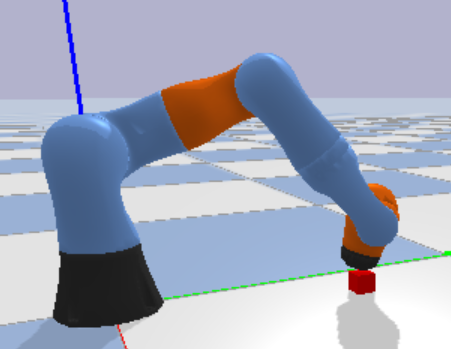

## MODELS


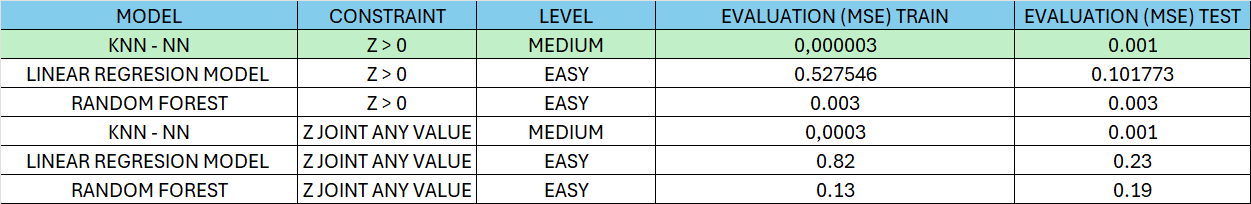

## DATA SET IK

FOWARD KINEMATICS

(q1, q2, q3) →  (x, y)

In [17]:
n_samples = 50000
X_positions = np.zeros((n_samples, 2), dtype=np.float32)  # XY positions (at Z=0)
Y_angles = np.zeros((n_samples, 3), dtype=np.float32)     # Joint angles

i = 0
while i < n_samples:
    
    q1 = random.uniform(q1_min, q1_max)
    q2 = random.uniform(q2_min, q2_max)
    q3 = random.uniform(q3_min, q3_max)
    
    
    z_joint = link2_length * math.sin(q2)
    if z_joint <= 0:  # Constraint
        continue
    
    
    z_end = link2_length * math.sin(q2) + link3_length * math.sin(q2 + q3)
    
    #if abs(z_end) > 0.20:  
     #   continue
    
    # Calculate XY position (forward kinematics)
    radius = link2_length * math.cos(q2) + link3_length * math.cos(q2 + q3)
    x = radius * math.cos(q1)
    y = radius * math.sin(q1)
    
    X_positions[i] = [x, y]
    Y_angles[i] = [q1, q2, q3]
    i += 1

print(f"Generated {n_samples} ")


Generated 50000 


## CREATE KNN - NN

### NORMALIZE DATA

[ normalized_x, normalized_y, knn_q1, knn_q2, knn_q3 ]



In [18]:
X_mean = X_positions.mean(axis=0, keepdims=True)
X_std = X_positions.std(axis=0, keepdims=True) + 1e-8
Y_mean = Y_angles.mean(axis=0, keepdims=True)
Y_std = Y_angles.std(axis=0, keepdims=True) + 1e-8

X_normalized = (X_positions - X_mean) / X_std
Y_normalized = (Y_angles - Y_mean) / Y_std
np.save("X_mean.npy", X_mean)
np.save("X_std.npy", X_std)
np.save("Y_mean.npy", Y_mean)
np.save("Y_std.npy", Y_std)


In [19]:
knn_k = 20  # Number of nearest neighbors

# Use sklearn's KNN model
knn_model = KNeighborsRegressor(n_neighbors=knn_k, weights='distance')
knn_model.fit(X_positions, Y_angles)
knn_predictions = knn_model.predict(X_positions)


joblib.dump(knn_model, "knn_ik_model.pkl")


# Normalize KNN predictions to match neural network scale
knn_normalized = (knn_predictions - Y_mean) / Y_std

In [20]:
print(knn_normalized)

[[ 1.52508174  1.48216772 -1.40167114]
 [-0.35194635 -1.64281635  1.07275168]
 [ 1.04552099  0.94223032 -1.67062493]
 ...
 [ 1.44620415  0.69591977  0.37622001]
 [-1.64293878 -1.14819681 -1.65371087]
 [-1.62068287  0.30843785  0.61151042]]


## PREPARE NEURAL NETWORK INPUT

In [21]:
# Combine normalized XY positions with KNN predictions
# This gives the network both the target position and a good initial guess
X_combined = np.concatenate([X_normalized, knn_normalized], axis=1)

# Neural network will predict the RESIDUAL (correction to KNN guess)
residual_targets = Y_normalized - knn_normalized

## BUILD NEURAL NETWORK

In [22]:
input_layer = layers.Input(shape=(5,), name='xy_knn')  # 2 XY + 3 KNN angles
hidden1 = layers.Dense(256, activation='relu')(input_layer)
hidden2 = layers.Dense(256, activation='relu')(hidden1)
output_layer = layers.Dense(3, name='residual')(hidden2)  # 3 joint angles correction

model = keras.Model(inputs=input_layer, outputs=output_layer)
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='mse')

print(model.summary())

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ xy_knn (InputLayer)             │ (None, 5)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ residual (Dense)                │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 68,099 (266.01 KB)

 Trainable params: 68,099 (266.01 KB)

 Non-trainable params: 0 (0.00 B)

None


## TRAIN NEURAL NETWORK

In [23]:
start_time = time.time()
# Callbacks to improve training
reduce_lr = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, 
                                        patience=10, min_lr=1e-6)
early_stop = callbacks.EarlyStopping(monitor='val_loss', patience=25, 
                                     restore_best_weights=True)

history = model.fit(
    X_combined, 
    residual_targets,
    epochs=10,
    batch_size=1024,
    validation_split=0.1,
    verbose=2,
    callbacks=[reduce_lr, early_stop]
)


end_time = time.time()
total_duration = (end_time - start_time)/60
model.save('iknet_keras_best.keras')
print("Model saved as 'iknet_keras_best.keras'")
print(f"Time {total_duration}")

Epoch 1/10
44/44 - 1s - 14ms/step - loss: 0.0013 - val_loss: 8.2391e-05 - learning_rate: 0.0010
Epoch 2/10
44/44 - 0s - 4ms/step - loss: 5.0120e-05 - val_loss: 3.0647e-05 - learning_rate: 0.0010
Epoch 3/10
44/44 - 0s - 4ms/step - loss: 2.4649e-05 - val_loss: 1.9856e-05 - learning_rate: 0.0010
Epoch 4/10
44/44 - 0s - 4ms/step - loss: 1.7398e-05 - val_loss: 1.5276e-05 - learning_rate: 0.0010
Epoch 5/10
44/44 - 0s - 3ms/step - loss: 1.3649e-05 - val_loss: 1.2229e-05 - learning_rate: 0.0010
Epoch 6/10
44/44 - 0s - 4ms/step - loss: 1.1226e-05 - val_loss: 1.0247e-05 - learning_rate: 0.0010
Epoch 7/10
44/44 - 0s - 4ms/step - loss: 9.5418e-06 - val_loss: 8.9658e-06 - learning_rate: 0.0010
Epoch 8/10
44/44 - 0s - 4ms/step - loss: 8.4114e-06 - val_loss: 8.1628e-06 - learning_rate: 0.0010
Epoch 9/10
44/44 - 0s - 5ms/step - loss: 7.5112e-06 - val_loss: 7.1716e-06 - learning_rate: 0.0010
Epoch 10/10
44/44 - 0s - 4ms/step - loss: 6.9172e-06 - val_loss: 6.6735e-06 - learning_rate: 0.0010
Model saved 

## TEST THE MODEL

In [24]:

model = keras.models.load_model("iknet_keras_best.keras")
knn_model = joblib.load("knn_ik_model.pkl")

X_mean = np.load("X_mean.npy")
X_std  = np.load("X_std.npy")
Y_mean = np.load("Y_mean.npy")
Y_std  = np.load("Y_std.npy")


# Generate a valid random test case

while True:
    q1_test = random.uniform(q1_min, q1_max)
    q2_test = random.uniform(q2_min, q2_max)
    q3_test = random.uniform(q3_min, q3_max)

    # Elbow above ground
    z_joint_test = link2_length * math.sin(q2_test)
    if z_joint_test <= 0:
        continue

    # End-effector at ground level
    z_test = (
        link2_length * math.sin(q2_test)
        + link3_length * math.sin(q2_test + q3_test)
    )
    if abs(z_test) <= 0.05:
        break

# Forward kinematics → XY target
radius_test = (
    link2_length * math.cos(q2_test)
    + link3_length * math.cos(q2_test + q3_test)
)
x_test = radius_test * math.cos(q1_test)
y_test = radius_test * math.sin(q1_test)

print("\n--- TRUE VALUES ---")
print(f"q1={q1_test:.4f}, q2={q2_test:.4f}, q3={q3_test:.4f}")
print(f"End-effector Z: {z_test:.4f} (ground level)")
print(f"Elbow Z:  {z_joint_test:.4f} (above ground)")
print(f"Target XY: x={x_test:.4f}, y={y_test:.4f}")


# Normalize XY input

x_norm = (np.array([[x_test, y_test]]) - X_mean) / X_std

# KNN coarse IK prediction
knn_pred = knn_model.predict([[x_test, y_test]])
knn_norm = (knn_pred - Y_mean) / Y_std

# Neural network residual correction
test_input = np.concatenate([x_norm, knn_norm], axis=1).astype(np.float32)
residual_pred = model.predict(test_input, verbose=0)

# Final IK prediction
prediction_norm = knn_norm + residual_pred
prediction = prediction_norm * Y_std + Y_mean
q1_pred, q2_pred, q3_pred = prediction[0]


# Forward kinematics check

radius_pred = (
    link2_length * math.cos(q2_pred)
    + link3_length * math.cos(q2_pred + q3_pred)
)
x_pred = radius_pred * math.cos(q1_pred)
y_pred = radius_pred * math.sin(q1_pred)
z_pred = (
    link2_length * math.sin(q2_pred)
    + link3_length * math.sin(q2_pred + q3_pred)
)
z_joint_pred = link2_length * math.sin(q2_pred)

print("\n--- PREDICTED VALUES ---")
print(f"q1={q1_pred:.4f}, q2={q2_pred:.4f}, q3={q3_pred:.4f}")
print(f"End-effector Z: {z_pred:.4f} "
      f"{'(at ground)' if abs(z_pred) < 0.1 else '(NOT at ground!)'}")
print(f"Elbow Z:        {z_joint_pred:.4f} "
      f"{'(above ground)' if z_joint_pred > 0 else '(BELOW ground!)'}")
print(f"Achieved XY:    x={x_pred:.4f}, y={y_pred:.4f}")
print(f"Position error: {math.hypot(x_pred - x_test, y_pred - y_test):.6f}")


--- TRUE VALUES ---
q1=-0.7574, q2=0.5453, q3=-1.0852
End-effector Z: 0.0047 (ground level)
Elbow Z:  0.5187 (above ground)
Target XY: x=1.2445, y=-1.1767

--- PREDICTED VALUES ---
q1=-0.7522, q2=0.5411, q3=-0.6534
End-effector Z: 0.4030 (NOT at ground!)
Elbow Z:        0.5151 (above ground)
Achieved XY:    x=1.3515, y=-1.2645
Position error: 0.138428


## VISUALIZE RESULTS

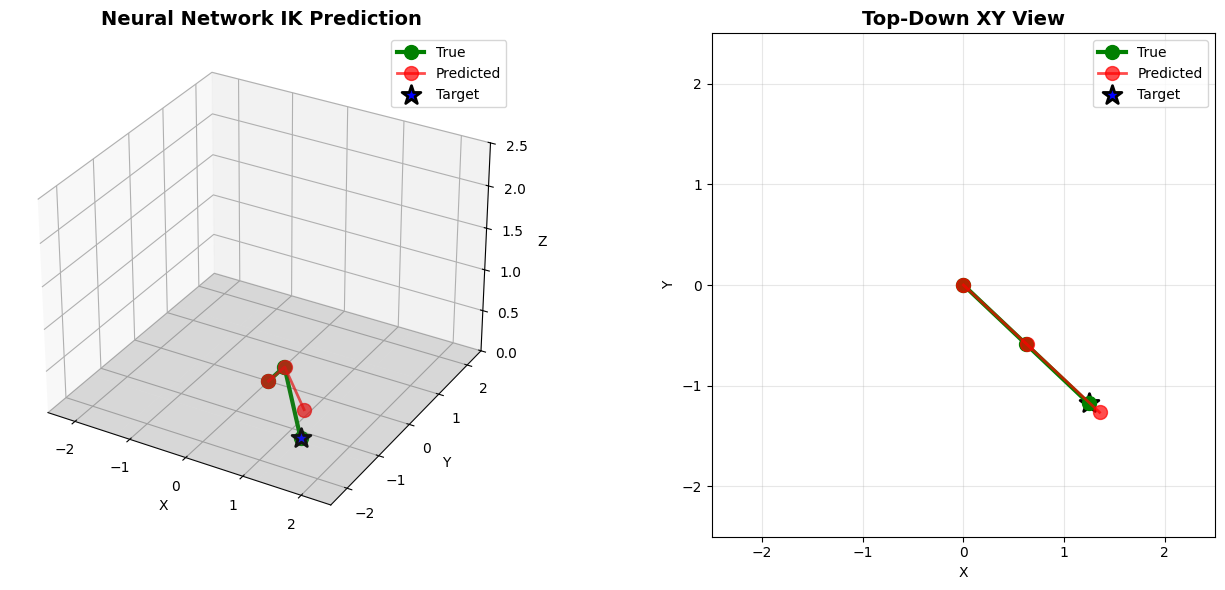

In [25]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D


# TRUE configuration
r1_true = link2_length * math.cos(q2_test)
x1_true = r1_true * math.cos(q1_test)
y1_true = r1_true * math.sin(q1_test)
z1_true = link2_length * math.sin(q2_test)

r2_true = link3_length * math.cos(q2_test + q3_test)
x2_true = (r1_true + r2_true) * math.cos(q1_test)
y2_true = (r1_true + r2_true) * math.sin(q1_test)
z2_true = link2_length * math.sin(q2_test) + link3_length * math.sin(q2_test + q3_test)

# PREDICTED configuration
r1_pred = link2_length * math.cos(q2_pred)
x1_pred = r1_pred * math.cos(q1_pred)
y1_pred = r1_pred * math.sin(q1_pred)
z1_pred = link2_length * math.sin(q2_pred)

r2_pred = link3_length * math.cos(q2_pred + q3_pred)
x2_pred = (r1_pred + r2_pred) * math.cos(q1_pred)
y2_pred = (r1_pred + r2_pred) * math.sin(q1_pred)
z2_pred = link2_length * math.sin(q2_pred) + link3_length * math.sin(q2_pred + q3_pred)


fig = plt.figure(figsize=(14, 6))

# --- LEFT: True vs Predicted ---
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
ax1.set_title("Neural Network IK Prediction", fontsize=14, fontweight='bold')

# True arm (green)
ax1.plot(
    [0, x1_true, x2_true],
    [0, y1_true, y2_true],
    [0, z1_true, z2_true],
    '-o', color='green', linewidth=3, markersize=10, label='True'
)

# Predicted arm (red)
ax1.plot(
    [0, x1_pred, x2_pred],
    [0, y1_pred, y2_pred],
    [0, z1_pred, z2_pred],
    '-o', color='red', linewidth=2, markersize=10, label='Predicted', alpha=0.7
)

# Target point
ax1.scatter(
    [x_test], [y_test], [z2_true],
    color='blue', s=200, marker='*',
    label='Target', edgecolors='black', linewidths=2
)

# Ground plane
xx, yy = np.meshgrid(np.linspace(-2.5, 2.5, 5), np.linspace(-2.5, 2.5, 5))
zz = np.zeros_like(xx)
ax1.plot_surface(xx, yy, zz, alpha=0.2, color='gray')

ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.set_zlabel("Z")
ax1.legend()
ax1.grid(True, alpha=0.3)

max_range = 2.5
ax1.set_xlim([-max_range, max_range])
ax1.set_ylim([-max_range, max_range])
ax1.set_zlim([0, max_range])

# --- RIGHT: XY top-down view ---
ax2 = fig.add_subplot(1, 2, 2)
ax2.set_title("Top-Down XY View", fontsize=14, fontweight='bold')

# True arm
ax2.plot([0, x1_true, x2_true], [0, y1_true, y2_true],
         '-o', color='green', linewidth=3, markersize=10, label='True')

# Predicted arm
ax2.plot([0, x1_pred, x2_pred], [0, y1_pred, y2_pred],
         '-o', color='red', linewidth=2, markersize=10, label='Predicted', alpha=0.7)

# Target
ax2.scatter([x_test], [y_test], color='blue', s=200, marker='*',
            edgecolors='black', linewidths=2, label='Target')

ax2.set_xlabel("X")
ax2.set_ylabel("Y")
ax2.grid(True, alpha=0.3)
ax2.legend()

ax2.set_xlim([-max_range, max_range])
ax2.set_ylim([-max_range, max_range])
ax2.set_aspect('equal')

plt.tight_layout()
plt.show()

## LINEAR REGRESION

In [26]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import numpy as np

# Train model
linear_model = LinearRegression()
linear_model.fit(X_positions, Y_angles)


train_pred = linear_model.predict(X_positions)
train_mse = mean_squared_error(Y_angles, train_pred)
print(f"Train MSE: {train_mse:.6f}")


test_xy = np.array([[x_test, y_test]], dtype=np.float32)
linear_pred = linear_model.predict(test_xy)

test_mse = mean_squared_error(
    np.array([[q1_test, q2_test, q3_test]]),
    linear_pred
)
print(f"Test MSE: {test_mse:.6f}")

print("Linear model prediction:", linear_pred)

Train MSE: 0.992833
Test MSE: 0.591781
Linear model prediction: [[-1.4936758e+00  7.7603757e-01  1.1095847e-03]]


## RANDOM FOREST

In [27]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
import numpy as np

rf_model = RandomForestRegressor(
    n_estimators=50,
    max_depth=20,
    random_state=42
)

rf_model.fit(X_positions, Y_angles)

train_pred = rf_model.predict(X_positions)
train_mse = mean_squared_error(Y_angles, train_pred)
print(f"Train MSE: {train_mse:.6f}")

test_xy = np.array([[x_test, y_test]], dtype=np.float32)
rf_pred = rf_model.predict(test_xy)

test_mse = mean_squared_error(
    np.array([[q1_test, q2_test, q3_test]]),
    rf_pred
)
print(f"Test MSE: {test_mse:.6f}")

print("Random Forest prediction:", rf_pred)

Train MSE: 0.150802
Test MSE: 0.054818
Random Forest prediction: [[-0.75014616  0.68654178 -0.70510662]]
